# Training and Evaluating a Neural Network in PyTorch
## Real-world problem: Is it a **Cat** or a **Dog**?

In the lectures we studied neural networks on paper: weights, forward propagation, loss, gradient descent.
Today we use those ideas on a **real problem** with **real photos**, using **PyTorch**, the deep learning library that most researchers and companies use.

### What you will learn today
1. How to use **Google Drive** with Colab so your data and models are **not lost** when Colab shuts down.
2. How to **download** and **unzip** a real dataset with Python code.
3. How to split data into **training**, **validation** and **test** sets, and why we need all three.
4. What **tensors**, **batches**, **iterations** and **epochs** are.
5. How to build a neural network (a **Multi-Layer Perceptron**, MLP) as a PyTorch class.
6. The **training loop**: forward pass → loss → backward pass → weight update.
7. **Early stopping**: stopping training at the right time.
8. **Training vs validation curves**: how to *see* over-fitting.
9. **Evaluation**: accuracy, **confusion matrix**, **precision**, **recall** and **F1 score**.

### Before you start
* If a GPU is available, choose **Runtime → Change runtime type → T4 GPU → Save**. **No GPU? No problem:** this notebook is designed to also run on the normal CPU runtime, just a bit slower.
* Run the cells **one by one, from top to bottom** (Shift + Enter). Read each comment before you run the cell.

> **Note:** Code lines that start with `#` are **comments**. Python ignores them. They are written for **you**, so read them carefully.

---
## Step 0: Check the hardware

Neural networks do a lot of matrix multiplications. A **GPU** (graphics card) can do thousands of them in parallel, so training is much faster on a GPU than on a CPU.

In [ ]:
# 'import' loads a library so that we can use it.
# torch = PyTorch, the deep learning library we will use today.
import torch

print("PyTorch version:", torch.__version__)

# torch.cuda.is_available() returns True if Colab has given us a GPU.
if torch.cuda.is_available():
    device = torch.device("cuda")          # "cuda" means: use the NVIDIA GPU
    print("GPU found:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")           # no GPU, so use the normal processor
    print("No GPU found. That is fine: everything works on the CPU, it is just slower.")

# Later we will send our model and our data to this 'device'.
print("We will use:", device)

PyTorch version: 2.11.0+cu130
GPU found: Tesla T4
We will use: cuda


---
## Step 1: Mount Google Drive

Colab gives you a **temporary** computer. When you close the tab or stay idle for some time, Colab **deletes everything** on it: downloaded data, trained models, results.

**Google Drive is permanent.** If we *mount* (connect) Drive, it appears as a normal folder at `/content/drive/MyDrive`. Anything we save there **stays** after Colab shuts down.

We will use Drive to keep:
* the downloaded dataset (so we download it **only once**), and
* our trained model (so we never need to train it again).

When you run the next cell, Google will ask for permission. Choose your account and click **Allow**.

In [ ]:
from google.colab import drive

# After this line, your Google Drive is available at the path /content/drive/MyDrive
drive.mount('/content/drive')

Mounted at /content/drive


---
## Step 2: Create a project folder in Drive

It is a good habit to keep each project in its own folder. We will create:

```
MyDrive/
└── ML/
 └── NN/
    └── cats_vs_dogs/      <- dataset zip and trained models will live here
```

In [ ]:
import os   # 'os' lets Python work with files and folders

# The folder where we keep everything for this project (inside Google Drive).
PROJECT_DIR = '/content/drive/MyDrive/ML/NN/cats_vs_dogs'

# makedirs creates the folder AND any missing parent folders (ML_Course too).
# exist_ok=True means: do not show an error if the folder already exists.
os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("It currently contains:", os.listdir(PROJECT_DIR))

Project folder: /content/drive/MyDrive/ML/NN/cats_vs_dogs
It currently contains: ['kagglecatsanddogs_5340.zip', 'mlp_cats_vs_dogs_best.pt']


---
## Step 3: Download the dataset

We use the **Microsoft Cats vs Dogs** dataset: about **25,000 photos** of cats and dogs, taken by ordinary people, in all sizes, poses and lighting. It is about **825 MB**.

The code below first checks whether the zip file is **already in your Drive**. If it is, it skips the download. This is why we saved it to Drive: next time you open this notebook, you will not wait for the download again.

In [ ]:
import urllib.request
import zipfile

DATA_URL = ('https://download.microsoft.com/download/3/E/1/'
            '3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip')
ZIP_PATH = os.path.join(PROJECT_DIR, 'kagglecatsanddogs_5340.zip')


def show_progress(block_num, block_size, total_size):
    # urllib calls this function again and again during the download.
    # We use it to print the progress every 10%.
    done = block_num * block_size
    percent = min(100, int(100 * done / total_size))
    if percent % 10 == 0 and percent != show_progress.last:
        print(f"  downloaded {percent:3d}%  ({done / 1e6:.0f} MB of {total_size / 1e6:.0f} MB)")
        show_progress.last = percent
show_progress.last = -1


# zipfile.is_zipfile checks that the file exists AND is a complete zip file.
# (If an earlier download stopped half way, the file is broken and we download it again.)
if zipfile.is_zipfile(ZIP_PATH):
    print("Dataset zip already in Drive, skipping download:", ZIP_PATH)
else:
    print("Downloading the dataset to Google Drive (about 1 to 3 minutes) ...")
    # We download to a temporary name first, and rename it only when the download is complete.
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH + '.part', reporthook=show_progress)
    os.replace(ZIP_PATH + '.part', ZIP_PATH)
    print("Download finished:", ZIP_PATH)

print(f"Zip size: {os.path.getsize(ZIP_PATH) / 1e6:.0f} MB")

Dataset zip already in Drive, skipping download: /content/drive/MyDrive/ML/NN/cats_vs_dogs/kagglecatsanddogs_5340.zip
Zip size: 825 MB


---
## Step 4: Unzip the dataset

**Important trick:** reading thousands of small files directly from Google Drive is **very slow**. So we keep the *zip* in Drive (permanent) but **unzip it to Colab's local disk** (`/content/data`), which is fast. The local copy is lost when Colab restarts, but unzipping again takes only about a minute.

In [ ]:
RAW_DIR = '/content/data/raw'                      # local (fast) disk, NOT Drive
PET_DIR = os.path.join(RAW_DIR, 'PetImages')       # the zip contains a folder called PetImages

if os.path.isdir(PET_DIR):
    print("Already unzipped:", PET_DIR)
else:
    print("Unzipping ... (about 1 minute)")
    with zipfile.ZipFile(ZIP_PATH) as zf:          # open the zip file
        zf.extractall(RAW_DIR)                     # extract everything into RAW_DIR
    print("Done.")

# Let us look at what we got.
for class_name in ['Cat', 'Dog']:
    folder = os.path.join(PET_DIR, class_name)
    jpgs = [f for f in os.listdir(folder) if f.lower().endswith('.jpg')]
    print(f"{class_name}: {len(jpgs)} images in {folder}")

Unzipping ... (about 1 minute)
Done.
Cat: 12500 images in /content/data/raw/PetImages/Cat
Dog: 12500 images in /content/data/raw/PetImages/Dog


---
## Step 5: Make a smaller, balanced dataset with train / validation / test splits

25,000 images would take a long time to train on in class, so we take a **random sample**:

| Split | Cats | Dogs | Total | Used for |
|---|---|---|---|---|
| **Train** | 1000 | 1000 | 2000 | learning the weights (the model *sees* these) |
| **Validation** | 250 | 250 | 500 | checking progress **during** training, early stopping, choosing settings |
| **Test** | 250 | 250 | 500 | the **final exam**: used **only once** at the very end |

### Why three sets?
* The model can **memorise** the training images. So training accuracy says *nothing* about how good the model is on new photos.
* We use the **validation** set to make decisions (when to stop, which settings are best). But because we made decisions with it, it is slightly "used".
* The **test** set is never used for any decision. It gives an **honest** estimate of performance on brand new photos. **Never tune your model using the test set.** That is cheating yourself.

Real-world data is messy: a few files in this dataset are **corrupted** (empty or broken). The code checks every image and skips broken ones.

In [ ]:
import random
import shutil
import warnings
from PIL import Image          # PIL (Pillow) is the standard Python library for opening images

# Some photos have slightly damaged metadata (EXIF). PIL prints warnings for them; we hide those.
warnings.filterwarnings('ignore', category=UserWarning)


def is_valid_image(path):
    # Try to open and fully decode the image. If anything fails, the file is broken.
    try:
        with Image.open(path) as img:
            img.convert('RGB')
        return True
    except Exception:
        return False


def build_subset(pet_dir, out_dir, n_train, n_val, n_test, seed):
    # Creates this folder structure (the format PyTorch's ImageFolder expects):
    #   out_dir/train/cat/*.jpg   out_dir/train/dog/*.jpg
    #   out_dir/val/cat/*.jpg     out_dir/val/dog/*.jpg
    #   out_dir/test/cat/*.jpg    out_dir/test/dog/*.jpg
    if os.path.isdir(out_dir):
        shutil.rmtree(out_dir)                       # start fresh every time
    rng = random.Random(seed)                        # random generator with a fixed seed -> same sample every run
    for raw_name, new_name in [('Cat', 'cat'), ('Dog', 'dog')]:
        src_folder = os.path.join(pet_dir, raw_name)
        files = sorted(f for f in os.listdir(src_folder) if f.lower().endswith('.jpg'))
        rng.shuffle(files)                           # random order
        needed = n_train + n_val + n_test
        chosen = []
        for f in files:                              # keep taking files until we have enough valid ones
            if is_valid_image(os.path.join(src_folder, f)):
                chosen.append(f)
            if len(chosen) == needed:
                break
        splits = {'train': chosen[:n_train],
                  'val':   chosen[n_train:n_train + n_val],
                  'test':  chosen[n_train + n_val:]}
        for split_name, names in splits.items():
            dst_folder = os.path.join(out_dir, split_name, new_name)
            os.makedirs(dst_folder, exist_ok=True)
            for f in names:
                shutil.copy(os.path.join(src_folder, f), os.path.join(dst_folder, f))
    print("Subset created in", out_dir)


DATA_DIR = '/content/data/cats_vs_dogs_small'
build_subset(PET_DIR, DATA_DIR, n_train=1000, n_val=250, n_test=250, seed=42)

# Count the images in every folder to make sure everything is right.
for split_name in ['train', 'val', 'test']:
    for class_name in ['cat', 'dog']:
        n = len(os.listdir(os.path.join(DATA_DIR, split_name, class_name)))
        print(f"{split_name:5s} / {class_name}: {n}")

Subset created in /content/data/cats_vs_dogs_small
train / cat: 1000
train / dog: 1000
val   / cat: 250
val   / dog: 250
test  / cat: 250
test  / dog: 250


### Look at the data first!
Always look at your data before training anything. Notice the photos have **different sizes**, backgrounds, poses and lighting. This is what makes the problem hard.

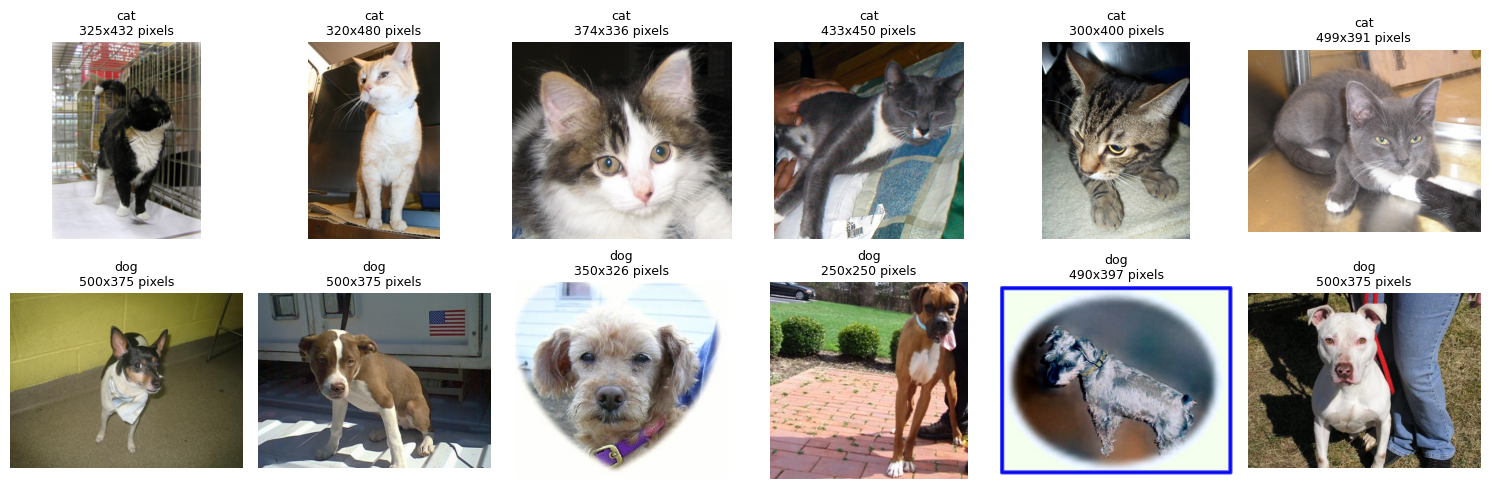

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for row, class_name in enumerate(['cat', 'dog']):
    folder = os.path.join(DATA_DIR, 'train', class_name)
    for col, fname in enumerate(sorted(os.listdir(folder))[:6]):
        img = Image.open(os.path.join(folder, fname))
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{class_name}\n{img.size[0]}x{img.size[1]} pixels", fontsize=9)
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

---
## Step 6: Tensors, PyTorch's basic data type

A **tensor** is just a multi-dimensional array of numbers (like a NumPy array), but it can live on the GPU and PyTorch can automatically compute **gradients** for it.

| Object | Tensor shape |
|---|---|
| a single number | `[]` |
| a vector of 5 numbers | `[5]` |
| a grey image, 64 × 64 | `[64, 64]` |
| a colour image (Red, Green, Blue channels) | `[3, 64, 64]` |
| a **batch** of 32 colour images | `[32, 3, 64, 64]` |

In [ ]:
x = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])
print("x =\n", x)
print("shape of x:", x.shape)          # 2 rows, 3 columns
print("x * 10 =\n", x * 10)            # element-wise operations work like NumPy

# A fake batch of 32 colour images, each 64x64, filled with random numbers:
fake_batch = torch.rand(32, 3, 64, 64)
print("\nshape of a batch of images:", fake_batch.shape)

# Moving a tensor to the GPU is one line:
x_gpu = x.to(device)
print("x now lives on:", x_gpu.device)

x =
 tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape of x: torch.Size([2, 3])
x * 10 =
 tensor([[10., 20., 30.],
        [40., 50., 60.]])

shape of a batch of images: torch.Size([32, 3, 64, 64])
x now lives on: cuda:0


---
## Step 7: From image files to tensors: `transforms`, `ImageFolder` and `DataLoader`

A neural network needs **numbers of a fixed size**, but our photos are JPEG files of all sizes. Three PyTorch tools fix this:

1. **`transforms`**: a recipe applied to every image:
   * `Resize((64, 64))`: make every image 64 × 64 pixels (small, so training is fast).
   * `ToTensor()`: convert the image to a tensor of shape `[3, 64, 64]` with values between 0 and 1.
   * `Normalize(mean, std)`: shift values to the range -1 to 1 (networks train better with centred inputs).
2. **`ImageFolder`**: reads a folder where **each sub-folder is a class**. Labels are given in alphabetical order: `cat → 0`, `dog → 1`.
3. **`DataLoader`**: groups images into **batches** and shuffles them.

In [ ]:
from torchvision import datasets, transforms

IMG_SIZE = 64

# The recipe applied to EVERY image when it is loaded.
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),            # any size -> 64 x 64
    transforms.ToTensor(),                              # PIL image -> tensor [3, 64, 64], values in [0, 1]
    transforms.Normalize(mean=[0.5, 0.5, 0.5],          # (value - 0.5) / 0.5  -> values in [-1, 1]
                         std=[0.5, 0.5, 0.5]),
])

# One ImageFolder dataset for each split.
train_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, 'train'), transform=transform)
val_dataset   = datasets.ImageFolder(os.path.join(DATA_DIR, 'val'),   transform=transform)
test_dataset  = datasets.ImageFolder(os.path.join(DATA_DIR, 'test'),  transform=transform)

print("Classes and their labels:", train_dataset.class_to_idx)
print("Number of images -> train:", len(train_dataset),
      "| val:", len(val_dataset), "| test:", len(test_dataset))

# A dataset behaves like a list: dataset[i] gives (image_tensor, label).
image, label = train_dataset[0]
print("\nOne example:")
print("  image tensor shape:", image.shape)
print("  smallest / largest value:", round(image.min().item(), 2), "/", round(image.max().item(), 2))
print("  label:", label, "=", train_dataset.classes[label])

Classes and their labels: {'cat': 0, 'dog': 1}
Number of images -> train: 2000 | val: 500 | test: 500

One example:
  image tensor shape: torch.Size([3, 64, 64])
  smallest / largest value: -0.98 / 0.96
  label: 0 = cat


### What is a batch? (Very important)

Gradient descent from the lectures updates the weights using the gradient of the loss. There are three choices for **how many images** we use for each update:

| Method | Images per update | Problem |
|---|---|---|
| Full-batch gradient descent | all 2000 | very slow per update, may not fit in GPU memory |
| Stochastic gradient descent | 1 | very noisy updates |
| **Mini-batch gradient descent** | e.g. **32** | **best of both: what everyone uses** |

Vocabulary:
* **Batch size** = number of images in one batch (we use 32).
* **Iteration (step)** = one weight update using one batch.
* **Epoch** = one full pass over **all** training images.

With 2000 training images and batch size 32: 2000 / 32 = 62.5, so **63 iterations make one epoch** (the last batch has only 16 images).

`shuffle=True` for training: the batches are different in every epoch, so the model cannot learn the order of the images.

In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

# num_workers=2: two background processes load the next images while the GPU is busy.
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Iterations (batches) per epoch:", len(train_loader))

# Take ONE batch from the loader to see what it looks like.
images, labels = next(iter(train_loader))
print("images shape:", images.shape, "  -> [batch size, colour channels, height, width]")
print("labels shape:", labels.shape)
print("labels in this batch:", labels.tolist())

Iterations (batches) per epoch: 63
images shape: torch.Size([32, 3, 64, 64])   -> [batch size, colour channels, height, width]
labels shape: torch.Size([32])
labels in this batch: [0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1]


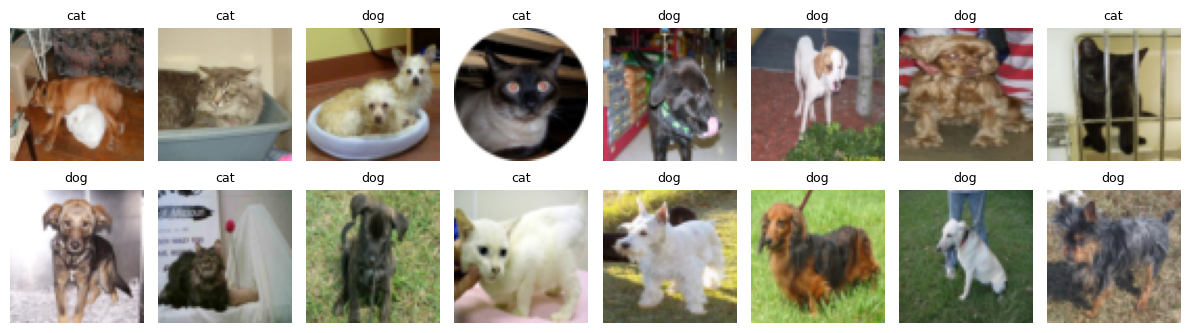

In [ ]:
# Show the 32 images of this batch. To display them we must undo the normalisation:
# we did (x - 0.5) / 0.5, so the reverse is x * 0.5 + 0.5.
def show_batch(images, labels, class_names, n=16):
    plt.figure(figsize=(12, 3.5))
    for i in range(n):
        plt.subplot(2, n // 2, i + 1)
        img = images[i] * 0.5 + 0.5                 # undo normalisation -> values in [0, 1]
        img = img.permute(1, 2, 0)                  # [3, 64, 64] -> [64, 64, 3], the order matplotlib wants
        plt.imshow(img.clamp(0, 1))
        plt.title(class_names[labels[i].item()], fontsize=9)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

show_batch(images, labels, train_dataset.classes)
# These are only 64 x 64 pixels, the size our network will see. Can YOU still tell cats from dogs?

---
## Step 8: Build the neural network

We build a **Multi-Layer Perceptron (MLP)**, the same kind of network as in our lectures:

```
image [3, 64, 64]
   │  flatten: 3 × 64 × 64 = 12,288 numbers in one long vector
   ▼
Linear 12288 → 512, then ReLU     (hidden layer 1, weight matrix W(1) has shape 512 × 12288)
   ▼
Linear 512 → 128, then ReLU       (hidden layer 2, W(2) has shape 128 × 512)
   ▼
Linear 128 → 1                    (output layer: ONE score, high = 'dog', low = 'cat')
```

In PyTorch a network is a **class** that inherits from `nn.Module`:
* `__init__` creates the layers (and their weights),
* `forward` describes how an input flows through the layers (forward propagation).

`nn.Linear(in, out)` computes `W x + b`. It creates and initialises the weights **W** and biases **b** for us.

Cat vs dog is a **binary** problem (two classes), so **one output neuron is enough**. Its output is called a **logit** (a raw score between −∞ and +∞).
Applying the **sigmoid** function $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ turns it into a probability between 0 and 1:
* $\sigma(z)$ = P(dog)  (class 1)
* $1 - \sigma(z)$ = P(cat)  (class 0)

A logit of 0 gives probability 0.5, so the rule is simply: **logit > 0 → dog, logit < 0 → cat**.

In [ ]:
import torch.nn as nn

class MLP(nn.Module):                               # our network IS-A nn.Module (inheritance!)
    def __init__(self, input_size=3 * IMG_SIZE * IMG_SIZE, hidden1=512, hidden2=128):
        super().__init__()                          # call the constructor of the parent class
        self.flatten = nn.Flatten()                 # [batch, 3, 64, 64] -> [batch, 12288]
        self.fc1 = nn.Linear(input_size, hidden1)   # fc = "fully connected" layer
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.fc3 = nn.Linear(hidden2, 1)            # ONE output neuron for a binary problem
        self.relu = nn.ReLU()                       # activation function: max(0, a)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))                  # hidden layer 1
        x = self.relu(self.fc2(x))                  # hidden layer 2
        x = self.fc3(x)                             # output layer: logit (no sigmoid here, see Step 9)
        return x.squeeze(1)                         # [batch, 1] -> [batch]: one number per image


torch.manual_seed(42)              # fix the random initial weights so everyone gets the same results
model = MLP().to(device)           # create the network and move its weights to the GPU
print(model)

# Count the weights and biases the network has to learn.
n_params = sum(p.numel() for p in model.parameters())
print(f"\nNumber of learnable parameters: {n_params:,}")
for name, p in model.named_parameters():
    print(f"  {name:12s} shape {str(list(p.shape)):15s} -> {p.numel():>10,} numbers")

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=12288, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=1, bias=True)
  (relu): ReLU()
)

Number of learnable parameters: 6,357,761
  fc1.weight   shape [512, 12288]    ->  6,291,456 numbers
  fc1.bias     shape [512]           ->        512 numbers
  fc2.weight   shape [128, 512]      ->     65,536 numbers
  fc2.bias     shape [128]           ->        128 numbers
  fc3.weight   shape [1, 128]        ->        128 numbers
  fc3.bias     shape [1]             ->          1 numbers


**6.3 million parameters** but only **2000** training images! A model with so many parameters can easily **memorise** the training images instead of learning general cat/dog features. Keep this in mind; we will see the effect in the curves (Step 12).

In [ ]:
# Forward pass on the batch from before (the network is still untrained = random weights).
images, labels = images.to(device), labels.to(device)     # data must be on the same device as the model

logits = model(images)                     # calling model(...) runs the forward() method
print("logits shape:", logits.shape, " -> [batch size]: one score per image")
print("logits of the first 3 images:", logits[:3].detach())

probs = torch.sigmoid(logits)             # sigmoid -> P(dog), a number between 0 and 1
print("\nP(dog) of the first 3 images:", probs[:3].detach())
print("(P(cat) = 1 - P(dog); an untrained network says about 50/50)")

predictions = (logits > 0).long()         # logit > 0  <=>  P(dog) > 0.5  ->  predict 1 (dog)
print("\npredicted classes:", predictions[:10].tolist())
print("true classes     :", labels[:10].tolist())

logits shape: torch.Size([32])  -> [batch size]: one score per image
logits of the first 3 images: tensor([0.0212, 0.0015, 0.0435], device='cuda:0')

P(dog) of the first 3 images: tensor([0.5053, 0.5004, 0.5109], device='cuda:0')
(P(cat) = 1 - P(dog); an untrained network says about 50/50)

predicted classes: [1, 1, 1, 0, 0, 1, 0, 1, 0, 0]
true classes     : [0, 0, 1, 0, 1, 1, 1, 0, 1, 0]


---
## Step 9: Loss function and optimizer

**Loss function: Binary Cross-Entropy (BCE).** For a two-class problem with one output $p = \sigma(z) = P(\text{dog})$ and true label $y \in \{0, 1\}$:
$$L = -\big[\, y \ln p + (1 - y) \ln(1 - p) \,\big]$$
Only one of the two terms is active for each image:
* true dog ($y = 1$): $L = -\ln p$ = $-\ln P(\text{dog})$
* true cat ($y = 0$): $L = -\ln(1 - p)$ = $-\ln P(\text{cat})$

So, just like before, the loss is $-\ln(\text{probability the model gives to the correct class})$:
* correct class gets probability 0.99 → loss = 0.01 (good)
* correct class gets probability 0.5 → loss = 0.69 (guessing)
* correct class gets probability 0.01 → loss = 4.6 (very bad)

We use `nn.BCEWithLogitsLoss`, which applies the **sigmoid** internally (this is numerically more stable than `sigmoid` followed by `nn.BCELoss`), which is why our network outputs a raw logit. For a batch it returns the **average** loss over the images.

**Important:** BCE expects the labels as **float** numbers (`0.0` / `1.0`) with the same shape as the outputs, so we write `labels.float()`.

**Optimizer.** The optimizer updates the weights using the gradients. Plain gradient descent is
$\mathbf{w}^{new} = \mathbf{w}^{old} - \eta \nabla L$. We use **Adam**, an improved version of gradient descent that adapts the step size of every weight automatically. It usually works well without much tuning. `lr` is the learning rate $\eta$.

In [ ]:
criterion = nn.BCEWithLogitsLoss()               # Binary Cross-Entropy (sigmoid included)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)    # model.parameters() = all W and b

loss = criterion(logits, labels.float())                     # BCE needs float labels: 0.0 / 1.0
print(f"Loss of the untrained network on this batch: {loss.item():.4f}")
print(f"For comparison, pure guessing gives -ln(0.5) = {-torch.log(torch.tensor(0.5)).item():.4f}")

Loss of the untrained network on this batch: 0.6925
For comparison, pure guessing gives -ln(0.5) = 0.6931


### The 5 lines at the heart of ALL deep learning

Every training step in PyTorch is these 5 lines:

```python
optimizer.zero_grad()                      # 1. clear the old gradients (PyTorch adds them up otherwise)
outputs = model(images)                    # 2. forward pass: compute predictions
loss = criterion(outputs, labels.float())  # 3. compute the loss (BCE needs float labels)
loss.backward()                            # 4. backward pass: compute dL/dw for EVERY weight (backpropagation)
optimizer.step()                           # 5. update every weight: w = w - lr * gradient (Adam's version)
```

`loss.backward()` does the whole **backpropagation** we derived by hand in class, for all 6.3 million weights, automatically. This is called **autograd**.



---
## Step 10: Functions for one training epoch and for evaluation

We now wrap the 5 lines in a loop over **all batches** = **one epoch**.

Two details:
* `model.train()` / `model.eval()` switch the model between training and evaluation mode. (Some layers we will meet later, like Dropout, behave differently in the two modes. It is good practice to always call them.)
* `torch.no_grad()` during evaluation: we are not updating weights, so PyTorch does not need to remember things for backpropagation. This saves memory and time.

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()                                   # training mode
    total_loss, total_correct, total_images = 0.0, 0, 0

    for images, labels in loader:                   # one iteration per batch
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()                       # 1. clear old gradients
        outputs = model(images)                     # 2. forward pass
        loss = criterion(outputs, labels.float())   # 3. loss (average over this batch)
        loss.backward()                             # 4. backpropagation
        optimizer.step()                            # 5. update weights

        # Keep running totals so we can report the average over the whole epoch.
        total_loss += loss.item() * images.size(0)            # .item() turns a 1-number tensor into a Python float
        total_correct += ((outputs > 0).long() == labels).sum().item()
        total_images += images.size(0)

    return total_loss / total_images, total_correct / total_images


def evaluate(model, loader, criterion, device):
    model.eval()                                    # evaluation mode
    total_loss, total_correct, total_images = 0.0, 0, 0

    with torch.no_grad():                           # no gradients needed: we only measure
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels.float())
            total_loss += loss.item() * images.size(0)
            total_correct += ((outputs > 0).long() == labels).sum().item()
            total_images += images.size(0)

    return total_loss / total_images, total_correct / total_images

---
## Step 11: Early stopping

How many epochs should we train? Too few → the model has not learned enough (**under-fitting**). Too many → it memorises the training images and gets **worse** on new images (**over-fitting**).

**Early stopping** answers this automatically:
* After every epoch, check the **validation loss**.
* If it is the best so far, **save a copy of the weights**.
* If it has **not improved for `patience` epochs** in a row, **stop** training.
* At the end, **go back to the saved best weights**.

```
validation loss
  │\
  │ \        best epoch: save weights here
  │  \__    ↓
  │     \__•__
  │           ‾‾--__        <- getting worse: over-fitting
  │                 ‾‾--     (stop after 'patience' bad epochs)
  └──────────────────────── epoch
```

In [ ]:
import copy

class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience            # how many bad epochs we accept before stopping
        self.min_delta = min_delta          # an improvement must be at least this big to count
        self.best_loss = float('inf')       # best validation loss so far (start: infinity)
        self.best_epoch = 0
        self.best_state = None              # copy of the best weights
        self.counter = 0                    # number of bad epochs in a row
        self.should_stop = False

    def step(self, val_loss, model, epoch):
        if val_loss < self.best_loss - self.min_delta:
            # Improvement: remember this loss and save a COPY of the weights.
            # (deepcopy is needed; otherwise we would only store a reference that keeps changing.)
            self.best_loss = val_loss
            self.best_epoch = epoch
            self.best_state = copy.deepcopy(model.state_dict())
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True

---
## Step 12: Train the network!

We start again from a **fresh** network (the one above already saw one batch 10 times).
Each epoch takes roughly 5 to 15 seconds on a GPU and 15 to 30 seconds on a CPU (much of the time goes into reading and resizing the JPEG files). The whole training takes about 3 to 8 minutes.

Read the printed numbers while it trains:
* `train loss` should keep going **down**.
* `val loss` goes down at first, and then starts going **up**. That is **over-fitting**.

In [ ]:
import time

torch.manual_seed(42)
model = MLP().to(device)                                       # fresh, untrained network
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

MAX_EPOCHS = 30
early_stopping = EarlyStopping(patience=5)

# We store the numbers of every epoch so that we can plot them afterwards.
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print(f"{'epoch':>5} | {'train loss':>10} {'train acc':>9} | {'val loss':>8} {'val acc':>7} | {'time':>5}")
print("-" * 60)
for epoch in range(1, MAX_EPOCHS + 1):
    start = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    early_stopping.step(val_loss, model, epoch)
    star = '  <- best so far' if early_stopping.best_epoch == epoch else ''
    print(f"{epoch:5d} | {train_loss:10.4f} {train_acc:9.3f} | {val_loss:8.4f} {val_acc:7.3f} | "
          f"{time.time() - start:4.1f}s{star}")

    if early_stopping.should_stop:
        print(f"\nEarly stopping: validation loss did not improve for {early_stopping.patience} epochs.")
        break

# Go back to the weights of the best epoch.
model.load_state_dict(early_stopping.best_state)
print(f"Best epoch: {early_stopping.best_epoch} (validation loss {early_stopping.best_loss:.4f}). "
      f"Best weights restored.")

epoch | train loss train acc | val loss val acc |  time
------------------------------------------------------------
    1 |     0.6772     0.572 |   0.6685   0.576 |  4.8s  <- best so far
    2 |     0.6031     0.672 |   0.6815   0.604 |  6.7s
    3 |     0.5590     0.718 |   0.6965   0.606 |  4.8s
    4 |     0.4953     0.769 |   0.6969   0.616 |  4.8s
    5 |     0.4334     0.813 |   0.7168   0.588 |  6.5s
    6 |     0.3987     0.840 |   0.7355   0.592 |  4.7s

Early stopping: validation loss did not improve for 5 epochs.
Best epoch: 1 (validation loss 0.6685). Best weights restored.


In [ ]:
# Save the best model to Google Drive, so it survives when Colab shuts down.
MODEL_PATH = os.path.join(PROJECT_DIR, 'mlp_cats_vs_dogs_best.pt')
torch.save(model.state_dict(), MODEL_PATH)
print("Model saved to Drive:", MODEL_PATH)

Model saved to Drive: /content/drive/MyDrive/ML/NN/cats_vs_dogs/mlp_cats_vs_dogs_best.pt


---
## Step 13: Training vs validation curves

These two plots are the most useful tool you have for diagnosing a neural network.

| What you see | Diagnosis |
|---|---|
| Both losses high and flat | **under-fitting**: the model is too simple or the learning rate is wrong |
| Both go down together and stay close | **good fit** |
| Train loss keeps falling, val loss **rises**, big gap between them | **over-fitting**: the model memorises the training data |

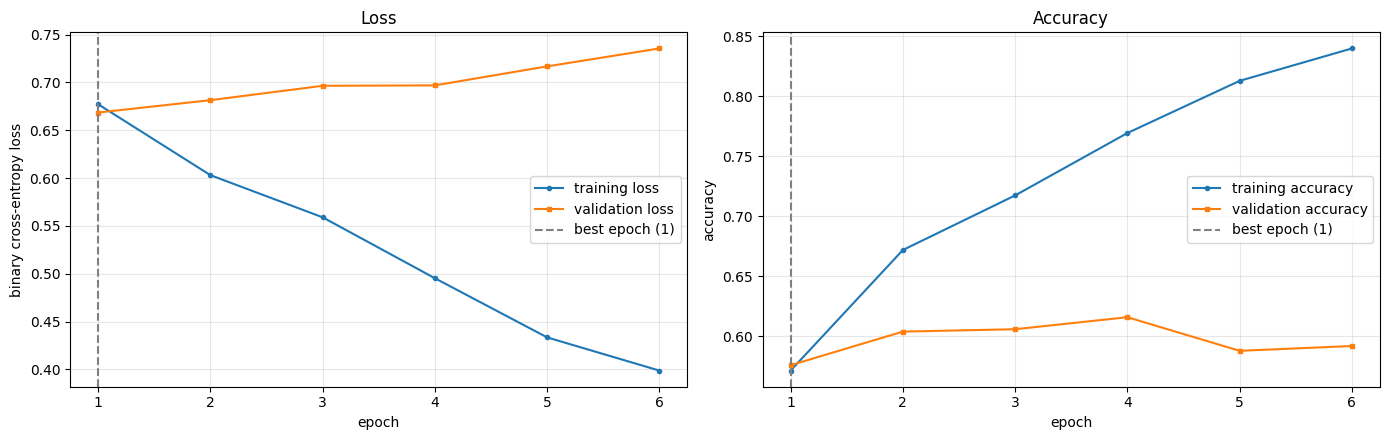

At the best epoch: train acc = 0.572, val acc = 0.576, gap = -0.004
At the last epoch: train acc = 0.840, val acc = 0.592, gap = 0.248


In [ ]:
epochs = range(1, len(history['train_loss']) + 1)
best = early_stopping.best_epoch

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(epochs, history['train_loss'], 'o-', label='training loss', markersize=3)
ax1.plot(epochs, history['val_loss'], 's-', label='validation loss', markersize=3)
ax1.axvline(best, color='gray', linestyle='--', label=f'best epoch ({best})')
ax1.set_xlabel('epoch'); ax1.set_ylabel('binary cross-entropy loss'); ax1.set_title('Loss')
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs, history['train_acc'], 'o-', label='training accuracy', markersize=3)
ax2.plot(epochs, history['val_acc'], 's-', label='validation accuracy', markersize=3)
ax2.axvline(best, color='gray', linestyle='--', label=f'best epoch ({best})')
ax2.set_xlabel('epoch'); ax2.set_ylabel('accuracy'); ax2.set_title('Accuracy')
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

i = best - 1
print(f"At the best epoch: train acc = {history['train_acc'][i]:.3f}, val acc = {history['val_acc'][i]:.3f}, "
      f"gap = {history['train_acc'][i] - history['val_acc'][i]:.3f}")
print(f"At the last epoch: train acc = {history['train_acc'][-1]:.3f}, val acc = {history['val_acc'][-1]:.3f}, "
      f"gap = {history['train_acc'][-1] - history['val_acc'][-1]:.3f}")

**Discussion.** You should see a clear case of **over-fitting**: the training accuracy keeps climbing towards 100% while the validation accuracy stops improving (around 60 to 65%) and the validation loss **rises**.
The network has 6.3 million parameters and only 2000 images, so it memorises them.

Early stopping saved us from the worst of it by keeping the weights of the best epoch. But the gap between training and validation is still there.
**Reducing this gap is the topic of our next lecture: Regularization**, and of **Assignment 2**.

---
## Step 14: Final evaluation on the TEST set

Now, and **only now**, we use the test set, **once**, with the best model.
We collect, for every test image: the true label, the predicted label, and the predicted probability of "dog".

In [ ]:
def get_predictions(model, loader, device):
    model.eval()
    all_labels, all_preds, all_probs = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            probs = torch.sigmoid(outputs)                     # probability of class 1 (= dog)
            all_labels.append(labels)
            all_preds.append((outputs > 0).long().cpu())       # logit > 0 -> dog; .cpu() brings results back from the GPU
            all_probs.append(probs.cpu())
    # torch.cat joins the list of per-batch tensors into one long tensor; .numpy() converts for scikit-learn
    return torch.cat(all_labels).numpy(), torch.cat(all_preds).numpy(), torch.cat(all_probs).numpy()


y_true, y_pred, y_prob = get_predictions(model, test_loader, device)
test_accuracy = (y_true == y_pred).mean()
print(f"Number of test images: {len(y_true)}")
print(f"Test accuracy: {test_accuracy:.3f}")

Number of test images: 500
Test accuracy: 0.598


### Confusion matrix

Accuracy alone hides **which** mistakes the model makes. The **confusion matrix** counts every combination of (true class, predicted class).

We call **dog** (label 1) the **positive** class and **cat** (label 0) the **negative** class:

|  | predicted cat | predicted dog |
|---|---|---|
| **true cat** | TN (true negative) | FP (false positive: a cat called "dog") |
| **true dog** | FN (false negative: a dog called "cat") | TP (true positive) |

TP = 151   TN = 148   FP = 102   FN = 99   (total = 500)

Confusion matrix from scikit-learn:
 [[148 102]
 [ 99 151]]


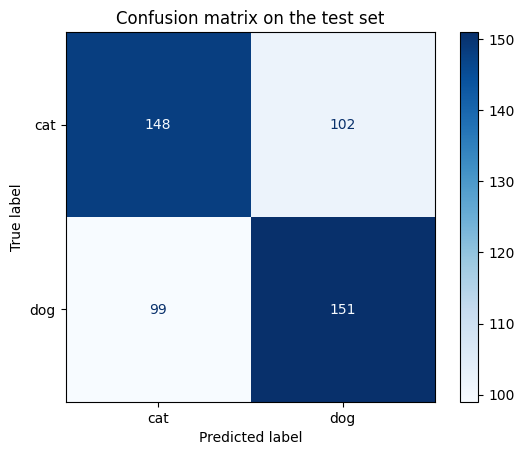

In [ ]:
# First, count the four cells by hand, so that you can see there is no magic.
TP = int(((y_pred == 1) & (y_true == 1)).sum())    # dogs correctly called dog
TN = int(((y_pred == 0) & (y_true == 0)).sum())    # cats correctly called cat
FP = int(((y_pred == 1) & (y_true == 0)).sum())    # cats wrongly called dog
FN = int(((y_pred == 0) & (y_true == 1)).sum())    # dogs wrongly called cat
print(f"TP = {TP}   TN = {TN}   FP = {FP}   FN = {FN}   (total = {TP + TN + FP + FN})")

# Then let scikit-learn compute and draw it.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)       # rows = true class, columns = predicted class
print("\nConfusion matrix from scikit-learn:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=test_dataset.classes)
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion matrix on the test set')
plt.show()

### Precision, recall and F1 score (positive class = dog)

$$\text{Precision} = \frac{TP}{TP + FP} \qquad \text{"When the model says dog, how often is it right?"}$$

$$\text{Recall} = \frac{TP}{TP + FN} \qquad \text{"Of all the real dogs, how many did the model find?"}$$

$$F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}} \qquad \text{"One number that is high only if BOTH are high"}$$

A model that calls **everything** "dog" has recall = 1.0 but terrible precision. A model that says "dog" only once, correctly, has precision = 1.0 but terrible recall. F1 punishes both.

In [ ]:
# By hand, from the formulas:
accuracy  = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
recall    = TP / (TP + FN) if (TP + FN) > 0 else 0.0
f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
print("Computed by hand (positive class = dog):")
print(f"  accuracy  = {accuracy:.3f}")
print(f"  precision = {precision:.3f}")
print(f"  recall    = {recall:.3f}")
print(f"  F1 score  = {f1:.3f}")

# The same with scikit-learn (they must match!):
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report
print("\nscikit-learn:")
print(f"  precision = {precision_score(y_true, y_pred):.3f}")
print(f"  recall    = {recall_score(y_true, y_pred):.3f}")
print(f"  F1 score  = {f1_score(y_true, y_pred):.3f}")

# classification_report shows the metrics for BOTH classes (each class in turn treated as positive).
print("\nFull report:\n")
print(classification_report(y_true, y_pred, target_names=test_dataset.classes, digits=3))

Computed by hand (positive class = dog):
  accuracy  = 0.598
  precision = 0.597
  recall    = 0.604
  F1 score  = 0.600

scikit-learn:
  precision = 0.597
  recall    = 0.604
  F1 score  = 0.600

Full report:

              precision    recall  f1-score   support

         cat      0.599     0.592     0.596       250
         dog      0.597     0.604     0.600       250

    accuracy                          0.598       500
   macro avg      0.598     0.598     0.598       500
weighted avg      0.598     0.598     0.598       500



---
## Step 15: Look at the mistakes

Numbers are not enough; look at **which** images the model gets wrong. You will often learn something (dark images? unusual poses? several animals?).

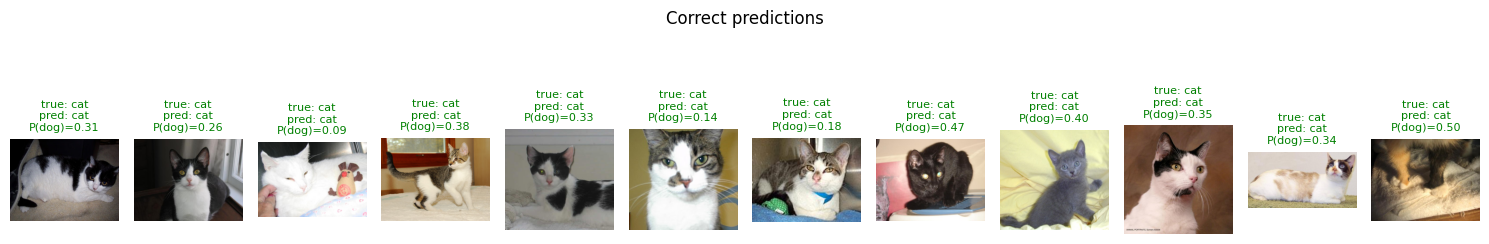

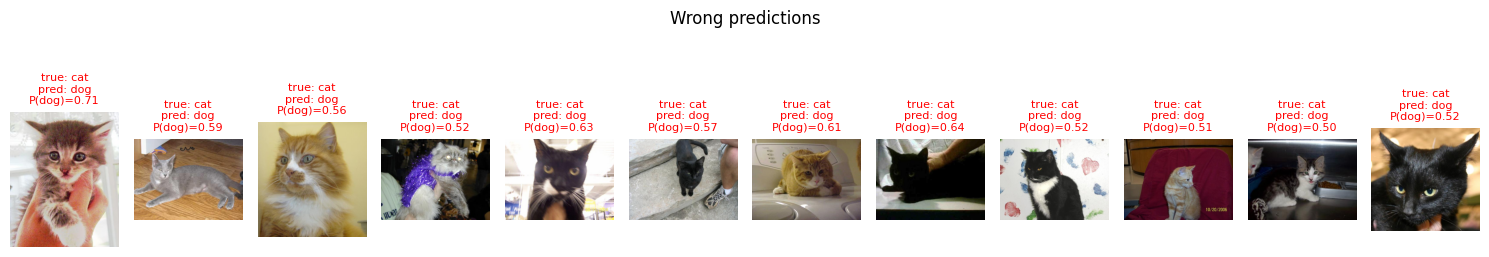

In [ ]:
def show_examples(dataset, y_true, y_pred, y_prob, wrong=True, n=12):
    idx = [i for i in range(len(y_true)) if (y_true[i] != y_pred[i]) == wrong][:n]
    plt.figure(figsize=(15, 3.2))
    for k, i in enumerate(idx):
        path, _ = dataset.samples[i]                    # original file of test image i
        plt.subplot(1, n, k + 1)
        plt.imshow(Image.open(path).convert('RGB'))
        names = dataset.classes
        plt.title(f"true: {names[y_true[i]]}\npred: {names[y_pred[i]]}\nP(dog)={y_prob[i]:.2f}",
                  fontsize=8, color='red' if wrong else 'green')
        plt.axis('off')
    plt.suptitle('Wrong predictions' if wrong else 'Correct predictions')
    plt.tight_layout()
    plt.show()

show_examples(test_dataset, y_true, y_pred, y_prob, wrong=False)
show_examples(test_dataset, y_true, y_pred, y_prob, wrong=True)

---
## Step 16: Load the saved model and use it on your own photo

Because we saved the model to Drive, we can load it at any time, even tomorrow, without training again.
Run the next cell and **upload any photo of a cat or a dog** (from your phone or the internet).

Model loaded from Drive.


Saving cat.jpeg to cat.jpeg


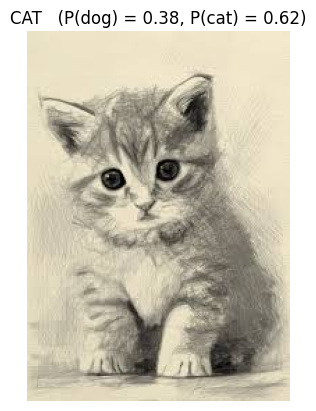

In [ ]:
# 1) Load the saved weights into a NEW model object.
loaded_model = MLP().to(device)
loaded_model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
loaded_model.eval()
print("Model loaded from Drive.")

# 2) Upload your own image(s).
from google.colab import files
uploaded = files.upload()                                   # opens a file chooser

for filename in uploaded:
    img = Image.open(filename).convert('RGB')
    x = transform(img).unsqueeze(0).to(device)              # same recipe as training; unsqueeze(0) adds a batch dimension -> [1, 3, 64, 64]
    with torch.no_grad():
        p_dog = torch.sigmoid(loaded_model(x))[0].item()
    answer = 'DOG' if p_dog >= 0.5 else 'CAT'
    plt.imshow(img); plt.axis('off')
    plt.title(f"{answer}   (P(dog) = {p_dog:.2f}, P(cat) = {1 - p_dog:.2f})")
    plt.show()

---
## Summary: the recipe for every supervised deep learning project

1. **Get the data** (store it permanently, e.g. in Drive) and **look at it**.
2. **Split** into train / validation / test. The test set is touched **once**.
3. Turn raw data into **tensors** of fixed size (`transforms`), group them into **batches** (`DataLoader`).
4. **Define the model** as an `nn.Module` class.
5. Choose a **loss** (binary cross-entropy for two classes, cross-entropy for more classes) and an **optimizer** (Adam / SGD).
6. **Training loop**: `zero_grad → forward → loss → backward → step`, for every batch, for many epochs.
7. Watch **training vs validation curves**; use **early stopping**.
8. **Evaluate** the best model on the test set: confusion matrix, precision, recall, F1.
9. **Save** the model.

Our model **over-fits**: train accuracy ≫ validation accuracy. Next lecture: **Regularization**, a set of techniques to fight over-fitting.

---
## Try it yourself (not graded)
1. Change `IMG_SIZE` to 32 (in Step 7) and run everything again. What happens to the number of parameters and to the accuracy?
2. Change the learning rate to `1e-2` and then to `1e-6`. Look at the curves. What goes wrong in each case?
3. Change `BATCH_SIZE` to 4 and to 256. How do the training time and the curves change?
4. In the confusion matrix, which mistake does your model make more often, cat → dog or dog → cat?